# Activity 2 — Exploratory analysis of washing-machine usage

**Goal:** Use the **official cleaned REFIT** data, aggregate each meter to **1-minute arithmetic mean power (W)**, identify appliance-use events, describe completeness/off time/hourly-weekday behavior, and compare cycle durations, peak W and estimated kWh across monitored homes. All results are calculated at runtime.

REFIT has **different washer-channel indices by house**. House **4** has two separately monitored washing machines (combined here to study *household washer demand*; the inferred "event" can therefore overlap multiple individual cycles). House **12** has no identified washer channel and House **14** does not exist.

In [1]:
from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

In [2]:
CLEAN_DATA_DIR = '../data/cleaned'

HOUSES = [1,2,3,4,5,6,7,8,9,10,11,13,15,16,17,18,19,20,21]
ANALYSIS_START = None   
ANALYSIS_END = None     

# Explicit, documented event-detection choices:
ACTIVE_W = 20.0             #Treat readings of at least 20 W as evidence of activity, while ignoring very low standby consumption
BRIDGE_OFF_MIN = 15         #Join active periods separated by pauses of up to 15 minutes
MIN_CYCLE_MIN = 15          #Exclude very short activity events unlikely to represent complete wash programs
MAX_CYCLE_MIN = 240         #Set an upper limit of four hours to filter unusually long detected events
MIN_CYCLE_KWH = 0.05        #Exclude low-energy events that might be standby or insignificant activity

In [3]:
Path(CLEAN_DATA_DIR)

WindowsPath('../data/cleaned')

In [ ]:
DATA_DIR = Path(CLEAN_DATA_DIR)
OUTPUT_DIR = Path('/refit_outputs')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

In [5]:
if not DATA_DIR.is_dir():
    raise FileNotFoundError(
        f'Extracted CSV folder not found: {DATA_DIR}.'
    )
CSV_FILES = sorted(p for p in DATA_DIR.rglob('*') if p.is_file() and p.suffix.lower() == '.csv')
print(f'Found {len(CSV_FILES)} CSV file(s) under {DATA_DIR}')
print('Sample names:', [str(p.relative_to(DATA_DIR)) for p in CSV_FILES[:5]])


COLS = ['Time', 'Unix', 'Aggregate'] + [f'Appliance{i}' for i in range(1, 10)] + ['Issues']


Found 20 CSV file(s) under ..\data\cleaned
Sample names: ['CLEAN_House1.csv', 'CLEAN_House10.csv', 'CLEAN_House11.csv', 'CLEAN_House12.csv', 'CLEAN_House13.csv']


In [6]:
def read_selected_chunks(path, channels, include_issues=True, chunksize=250_000):
    chosen = ['Time', 'Aggregate'] + [f'Appliance{i}' for i in channels]
    if include_issues:
        chosen += ['Issues']
    for chunk in pd.read_csv(
        path, header=None, names=(COLS if include_issues else COLS[:-1]),
        usecols=chosen, chunksize=chunksize, low_memory=False,
        skipinitialspace=True, on_bad_lines='warn'
    ):
        # Some CSVs have a header row. Such rows parse to NaT and are discarded.
        chunk['Time'] = pd.to_datetime(chunk['Time'], format='%Y-%m-%d %H:%M:%S', errors='coerce')
        chunk = chunk.dropna(subset=['Time'])
        for name in chosen[1:]:
            chunk[name] = pd.to_numeric(chunk[name], errors='coerce')
        yield chunk

In [7]:
HOUSES=[1,2,3,4,5,6,7,8,9,10,11,13,15,16,17,18,19,20,21]
WASHER_CHANNELS={1:[5],2:[2],3:[6],4:[4,5],5:[3],6:[2],7:[5],8:[4],9:[3],
                 10:[5],11:[3],13:[3],15:[3],16:[5],17:[4],18:[5],19:[2],20:[4],21:[3]}

In [9]:
def get_clean_file(house):
    pattern = re.compile(r'(?i)house[_\s-]?' + str(house) + r'(?!\d)')
    matches = [p for p in CSV_FILES if pattern.search(p.stem)]
    preferred = [p for p in matches if 'clean' in p.name.lower() or
                 any('clean' in part.lower() for part in p.parts[-3:-1])]
    if preferred:
        matches = preferred
    if not matches:
        raise FileNotFoundError(
            f'No cleaned CSV found for House {house} below {DATA_DIR}. '
        )
    if len(matches) > 1:
        raise RuntimeError(
            f'Found multiple possible cleaned files for House {house}: {matches}. '
        )
    return matches[0]

missing = []
check_rows = []
for h in HOUSES:
    if h not in WASHER_CHANNELS:
        raise ValueError(f'House {h} has no configured washing-machine channel.')
    try:
        f = get_clean_file(h)
        check_rows.append({'house': h, 'washer_channels': WASHER_CHANNELS[h],
                           'clean_csv': str(f.relative_to(DATA_DIR))})
    except FileNotFoundError as exc:
        missing.append(str(exc))
if missing:
    raise FileNotFoundError('Some selected households are missing:\n' + '\n'.join(missing))
display(pd.DataFrame(check_rows))
print(f'\nVerified: all {len(HOUSES)} selected homes have cleaned REFIT CSV files. Ready for analysis.')

,house,washer_channels,clean_csv
0,1,[5],CLEAN_House1.csv
1,2,[2],CLEAN_House2.csv
2,3,[6],CLEAN_House3.csv
3,4,"[4, 5]",CLEAN_House4.csv
4,5,[3],CLEAN_House5.csv
5,6,[2],CLEAN_House6.csv
6,7,[5],CLEAN_House7.csv
7,8,[4],CLEAN_House8.csv
8,9,[3],CLEAN_House9.csv
9,10,[5],CLEAN_House10.csv



Verified: all 19 selected homes have cleaned REFIT CSV files. Ready for analysis.


In [10]:
def load_clean_minutes(house, start=None, end=None):
    """Stream cleaned CSV; return observed per-minute mean watts without zero-filling outages."""
    chan = WASHER_CHANNELS[house]
    path = get_clean_file(house)
    pieces = []; first = None; last = None; parsed = 0
    for c in read_selected_chunks(path, chan, include_issues=True):
        if start is not None:
            c = c[c.Time >= pd.Timestamp(start)]
        if end is not None:
            c = c[c.Time < pd.Timestamp(end)]
        if c.empty:
            continue
        parsed += len(c)
        first = c.Time.min() if first is None else min(first, c.Time.min())
        last = c.Time.max() if last is None else max(last, c.Time.max())
        c['Aggregate'] = c['Aggregate'].where(c['Aggregate'].between(0, 25000))
        wm_cols = [f'Appliance{i}' for i in chan]
        for k in wm_cols:
            c[k] = c[k].where(c[k].between(0, 4000))
        # For House 4 both channels must be present to claim a total washing-machine reading.
        c['wm'] = c[wm_cols].sum(axis=1, min_count=len(chan))
        c['issues'] = c['Issues'].fillna(0).gt(0).astype(int)
        c['minute'] = c.Time.dt.floor('min')
        b = c.groupby('minute', sort=True).agg(
            agg_sum=('Aggregate','sum'), agg_n=('Aggregate','count'),
            wm_sum=('wm','sum'), wm_n=('wm','count'),
            issue_n=('issues','sum'), rows=('wm','size')
        )
        pieces.append(b)
    if not pieces:
        raise ValueError(f'No cleaned data for House {house} in the requested date range.')
    # Recombine sums and counts across chunk boundaries for correct 1-minute means.
    agg = pd.concat(pieces).groupby(level=0).sum().sort_index()
    minute = pd.DataFrame(index=agg.index)
    minute['aggregate_w'] = (agg.agg_sum / agg.agg_n.replace(0, np.nan)).astype('float32')
    minute['washer_w'] = (agg.wm_sum / agg.wm_n.replace(0, np.nan)).astype('float32')
    minute['issues_flag'] = agg.issue_n.gt(0)
    minute['observed_rows'] = agg.rows.astype('int32')
    minute = minute.asfreq('1min')
    minute['issues_flag'] = minute['issues_flag'].astype('boolean').fillna(False).astype(bool)
    minute['observed_rows'] = minute['observed_rows'].fillna(0).astype('int32')
    print(f'House {house}: {parsed:,} readings | {len(minute):,} minute slots | '
          f'{first} to {last} | {len(chan)} washer channel(s)')
    return minute

## 1. Event-detection rule

In [11]:
def detect_cycles(minute,house):
    """Morphological rule: >=ACTIVE_W, bridge <=BRIDGE_OFF_MIN off minutes, reject short/tiny/long events."""
    wm=minute.washer_w.to_numpy(dtype=float)
    valid=np.isfinite(wm)
    active=(wm>=ACTIVE_W)&valid
    # Work over maximal valid runs. Never bridge gaps with missing washer labels.
    edges=np.diff(np.r_[False,valid,False].astype('int8'))
    for a,b in zip(np.flatnonzero(edges==1),np.flatnonzero(edges==-1)):
        segment=active[a:b]
        off=~segment
        change=np.diff(np.r_[False,off,False].astype('int8'))
        for x,y in zip(np.flatnonzero(change==1),np.flatnonzero(change==-1)):
            if x>0 and y<len(segment) and y-x<=BRIDGE_OFF_MIN:
                active[a+x:a+y]=True
    starts_ends=np.diff(np.r_[False,active,False].astype('int8'))
    starts=np.flatnonzero(starts_ends==1); ends=np.flatnonzero(starts_ends==-1)
    events=[]
    for a,b in zip(starts,ends):
        duration=b-a
        energy=float(np.nansum(wm[a:b])/(60*1000))
        if not (MIN_CYCLE_MIN<=duration<=MAX_CYCLE_MIN and energy>=MIN_CYCLE_KWH): continue
        events.append({'house':house,'start':minute.index[a],'end_exclusive':minute.index[b-1]+pd.Timedelta(minutes=1),
                       'duration_min':duration,'peak_w':float(np.nanmax(wm[a:b])),
                       'energy_kwh':energy})
    return pd.DataFrame(events,columns=['house','start','end_exclusive','duration_min','peak_w','energy_kwh'])

In [12]:
house1_preview = load_clean_minutes(1, ANALYSIS_START, ANALYSIS_END)
display(house1_preview.head(10))
print('Missing washer minutes:', house1_preview.washer_w.isna().sum())
print('Valid washer minutes:', house1_preview.washer_w.notna().sum())
del house1_preview


House 1: 6,960,008 readings | 920,091 minute slots | 2013-10-09 13:06:17 to 2015-07-10 11:56:32 | 1 washer channel(s)


,aggregate_w,washer_w,issues_flag,observed_rows
minute,,,,
2013-10-09 13:06:00,529.666687,0.0,False,3
2013-10-09 13:07:00,543.875000,0.0,False,8
2013-10-09 13:08:00,578.000000,0.0,False,10
2013-10-09 13:09:00,638.299988,0.0,False,10
2013-10-09 13:10:00,800.200012,0.0,False,10
2013-10-09 13:11:00,854.200012,0.0,False,10
2013-10-09 13:12:00,1302.300049,0.0,False,10
2013-10-09 13:13:00,1429.000000,0.0,False,10
2013-10-09 13:14:00,1346.699951,0.0,False,10


Missing washer minutes: 116318
Valid washer minutes: 803773


## 2. Stream the selected homes; report true coverage, quality and cycles

In [18]:
quality_rows=[]; event_tables=[]; minute_samples={}; hourly_tables=[]; weekday_tables=[]
for house in HOUSES:
    assert house in WASHER_CHANNELS, f'House {house} does not have a documented washing-machine meter.'
    try:
        minute=load_clean_minutes(house,ANALYSIS_START,ANALYSIS_END)
    except ValueError as err:
        print('Skipping:',err); continue
    valid=minute.washer_w.notna() & minute.aggregate_w.notna()
    measured=minute.loc[valid]
    event=detect_cycles(minute,house)
    if len(event): event_tables.append(event)
    quality_rows.append({'house':house,'washer_channel(s)':','.join(map(str,WASHER_CHANNELS[house])),
        'first':str(minute.index.min()),'last':str(minute.index.max()),'total_minutes':len(minute),
        'valid_paired_minutes':int(valid.sum()),'missing_paired_minutes':int((~valid).sum()),
        'missing_pct':round(100*(~valid).mean(),2),'off_pct_among_valid':round(100*(measured.washer_w<ACTIVE_W).mean(),2) if len(measured) else np.nan,
        'issues_flagged_minutes':int(minute.issues_flag.sum()),'detected_cycles':len(event),
        'observed_washer_kwh':float(measured.washer_w.sum()/60000)})
    if len(measured):
        hourly_tables.append(measured.groupby(measured.index.hour)['washer_w'].agg(['mean','count']).assign(house=house).rename_axis('hour').reset_index())
        weekday_tables.append(measured.groupby(measured.index.dayofweek)['washer_w'].agg(['mean','count']).assign(house=house).rename_axis('weekday').reset_index())
    if len(minute_samples)<5: minute_samples[house]=minute  # enough for representative plots
quality_df=pd.DataFrame(quality_rows)
if quality_df.empty: raise RuntimeError('No eligible house loaded; check data files and date filters.')
cycles=pd.concat(event_tables,ignore_index=True) if event_tables else pd.DataFrame(columns=['house','start','end_exclusive','duration_min','peak_w','energy_kwh'])
print('Analysis homes:',quality_df.house.tolist())
display(quality_df)
print('Detected activity events:',len(cycles))
if len(cycles): display(cycles.groupby('house')[['duration_min','peak_w','energy_kwh']].agg(['count','median','mean']).round(2))
quality_df.to_csv(OUTPUT_DIR/'02_coverage_quality.csv',index=False)
cycles.to_csv(OUTPUT_DIR/'02_cycles.csv',index=False)

House 1: 6,960,008 readings | 920,091 minute slots | 2013-10-09 13:06:17 to 2015-07-10 11:56:32 | 1 washer channel(s)
House 2: 5,733,526 readings | 889,078 minute slots | 2013-09-17 22:08:11 to 2015-05-28 08:05:43 | 1 washer channel(s)
House 3: 6,994,594 readings | 885,095 minute slots | 2013-09-25 19:21:09 to 2015-06-02 10:55:42 | 1 washer channel(s)
House 4: 6,760,511 readings | 912,939 minute slots | 2013-10-11 10:19:17 to 2015-07-07 09:57:38 | 2 washer channel(s)
House 5: 7,430,755 readings | 933,593 minute slots | 2013-09-26 09:56:09 to 2015-07-06 17:48:55 | 1 washer channel(s)
House 6: 6,241,971 readings | 831,480 minute slots | 2013-11-28 12:15:35 to 2015-06-28 22:14:45 | 1 washer channel(s)
House 7: 6,756,034 readings | 882,970 minute slots | 2013-11-01 22:01:18 to 2015-07-08 02:10:54 | 1 washer channel(s)
House 8: 6,118,469 readings | 799,284 minute slots | 2013-11-01 22:13:18 to 2015-05-10 23:36:10 | 1 washer channel(s)
House 9: 6,169,525 readings | 818,007 minute slots | 201

,house,washer_channel(s),first,last,total_minutes,valid_paired_minutes,missing_paired_minutes,missing_pct,off_pct_among_valid,issues_flagged_minutes,detected_cycles,observed_washer_kwh
0,1,5,2013-10-09 13:06:00,2015-07-10 11:56:00,920091,803773,116318,12.64,98.12,16686,372,145.839386
1,2,2,2013-09-17 22:08:00,2015-05-28 08:05:00,889078,670164,218914,24.62,95.31,13458,325,202.055450
2,3,6,2013-09-25 19:21:00,2015-06-02 10:55:00,885095,784285,100810,11.39,94.34,60633,639,374.539093
3,4,"4,5",2013-10-11 10:19:00,2015-07-07 09:57:00,912939,787972,124967,13.69,98.54,24364,254,193.891068
4,5,3,2013-09-26 09:56:00,2015-07-06 17:48:00,933593,846373,87220,9.34,92.10,70888,676,445.555481
5,6,2,2013-11-28 12:15:00,2015-06-28 22:14:00,831480,704709,126771,15.25,98.12,14524,119,83.181061
6,7,5,2013-11-01 22:01:00,2015-07-08 02:10:00,882970,771928,111042,12.58,91.63,35837,837,488.640991
7,8,4,2013-11-01 22:13:00,2015-05-10 23:36:00,799284,717221,82063,10.27,96.68,12331,372,350.452759
8,9,3,2013-12-17 17:26:00,2015-07-08 18:52:00,818007,692184,125823,15.38,97.32,16534,243,173.618988
9,10,5,2013-11-20 11:31:00,2015-06-30 11:07:00,845257,750586,94671,11.20,91.27,13975,582,405.681580


Detected activity events: 6581


duration_min                peak_w                   energy_kwh         \
             count median    mean  count   median     mean      count median   
house                                                                          
1              372   33.0   43.52    372  2327.11  2291.16        372   0.32   
2              325   96.0  101.55    325  2090.20  2015.20        325   0.61   
3              639   66.0   69.60    639  1928.67  1915.64        639   0.56   
4              254   54.0   54.57    254  2556.06  2597.01        254   0.72   
5              676   48.0   63.63    676  2069.25  1822.00        676   0.29   
6              119  116.0  103.19    119  2051.89  1888.75        119   0.67   
7              837   60.0   76.82    837  2082.11  2062.26        837   0.55   
8              372   59.0   64.82    372  2336.93  2303.86        372   0.79   
9              243   74.0   76.46    243  2210.20  2171.77        243   0.66   
10             582  120.0  111.16    582  2053.00  1977.92        582   0.71   
11              76  103.0   83.71     76  2313.72  2232.97         76   0.52   
13             441   68.0   63.90    441  2125.00  2034.18        441   0.43   
15             249   92.0   89.49    249  2180.89  2078.05        249   0.70   
16             308   73.0   78.02    308  2049.68  2018.04        308   0.63   
17             278   61.0   58.10    278  2045.63  1958.30        278   0.39   
18             134   48.0   54.05    134  2190.67  2157.22        134   0.32   
19             257  102.0   94.47    257  1753.67  1659.18        257   0.24   
20             189   74.0   83.63    189  2271.88  2213.04        189   0.38   
21             230   86.0   89.65    230  2143.68  2119.44        230   0.62   

             
       mean  
house        
1      0.38  
2      0.61  
3      0.58  
4      0.73  
5      0.42  
6      0.64  
7      0.57  
8      0.93  
9      0.71  
10     0.66  
11     0.67  
13     0.44  
15     0.79  
16     0.66  
17     0.39  
18     0.36  
19     0.26  
20     0.44  
21     0.66

## 3. Required plot (i): representative 24-hour aggregate and washing-machine trace

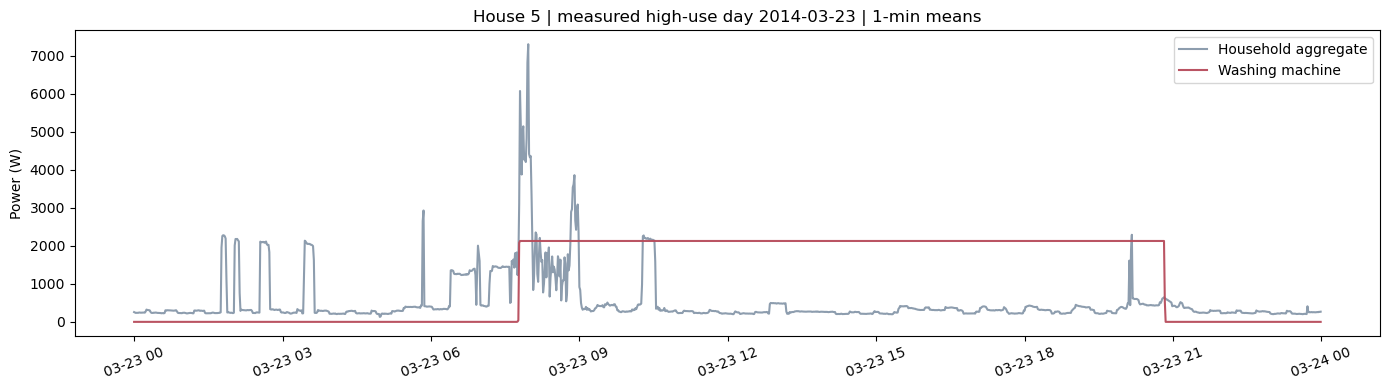

In [ ]:
rank=[]
for h,m in minute_samples.items():
    e=m.washer_w.resample('1D').sum(min_count=1).dropna()
    if len(e): 
        rank.append((float(e.max()),h,e.idxmax()))
if not rank: 
    raise RuntimeError('No washer data available for required plot.')
_,chosen_house,day=max(rank,key=lambda x:x[0])
trace=minute_samples[chosen_house]
slice24=trace.loc[day:day+pd.Timedelta(days=1)-pd.Timedelta(minutes=1)]


fig,ax=plt.subplots(figsize=(14,4))
ax.plot(slice24.index,slice24.aggregate_w,label='Household aggregate',alpha=.75,color='#677c93')
ax.plot(slice24.index,slice24.washer_w,label='Washing machine',alpha=.95,color='#b74b5b')
ax.set(ylabel='Power (W)',title=f'House {chosen_house} | measured high-use day {day:%Y-%m-%d} | 1-min means')
ax.legend(); plt.xticks(rotation=20) 
plt.tight_layout()
plt.savefig(OUTPUT_DIR/'02_trace_24h.png',dpi=160)
plt.show()

## 4. Required plot (ii): one detected event / cycle and its energy

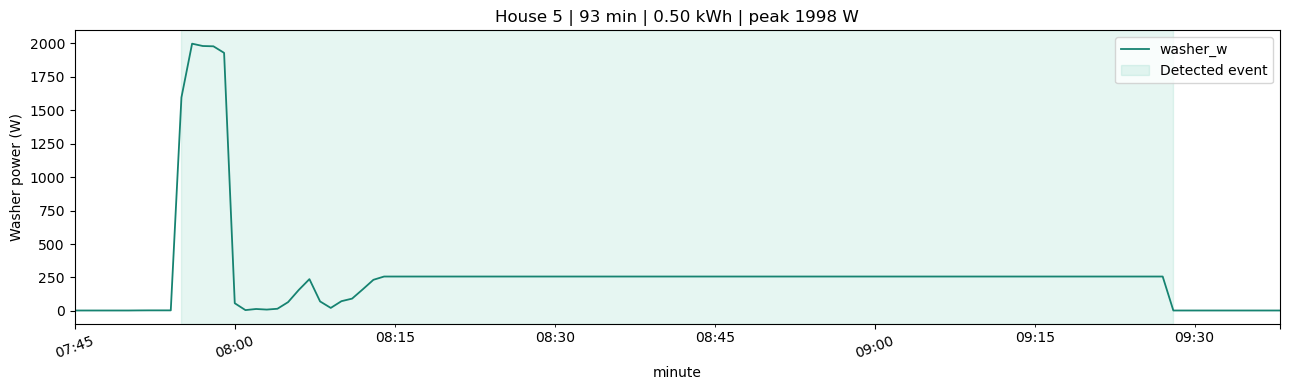

In [24]:
plot_candidates=cycles[cycles.house.isin(minute_samples)]
if len(plot_candidates):
    c=plot_candidates.iloc[(plot_candidates.energy_kwh-plot_candidates.energy_kwh.median()).abs().argmin()]
    m=minute_samples[int(c.house)]
    data=m.loc[c.start-pd.Timedelta(minutes=10):c.end_exclusive+pd.Timedelta(minutes=10),'washer_w']
    fig,ax=plt.subplots(figsize=(13,4))
    data.plot(ax=ax,color='#168371',lw=1.3)
    ax.axvspan(c.start,c.end_exclusive,color='#0aa982',alpha=.10,label='Detected event')
    ax.set(ylabel='Washer power (W)',title=f'House {int(c.house)} | {c.duration_min} min | {c.energy_kwh:.2f} kWh | peak {c.peak_w:.0f} W')
    ax.legend(); plt.xticks(rotation=20); plt.tight_layout()
    plt.savefig(OUTPUT_DIR/'02_cycle_trace.png',dpi=160);plt.show()
    
else: 
    print('No eligible detected event in retained plot homes. Relax heuristics only with a documented justification.')

## 5. Required plot (iii): observed-hour-normalized usage by hour and weekday

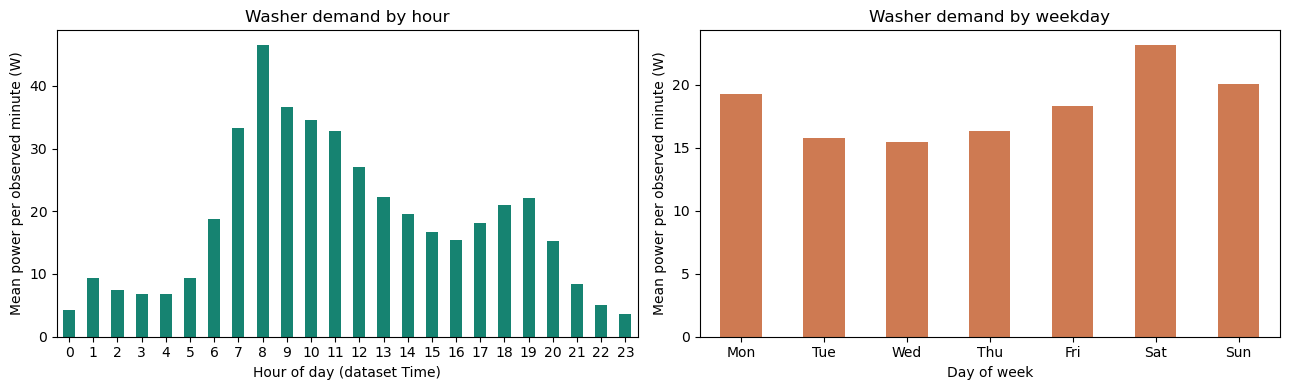

Highest observed mean washer-power hour: 08:00; weekday: Sat.


In [26]:
# Weight by the number of valid minutes across houses so missing periods do not count as off.
H=pd.concat(hourly_tables,ignore_index=True); D=pd.concat(weekday_tables,ignore_index=True)
def pooled_means(x,category):
    g=x.assign(weighted=x['mean']*x['count']).groupby(category)[['weighted','count']].sum()
    return g.weighted/g['count']
hourly=pooled_means(H,'hour').reindex(range(24))
weekday=pooled_means(D,'weekday').reindex(range(7))
fig,axes=plt.subplots(1,2,figsize=(13,4))
hourly.plot.bar(ax=axes[0],color='#168371',rot=0);axes[0].set(xlabel='Hour of day (dataset Time)',ylabel='Mean power per observed minute (W)',title='Washer demand by hour')
weekday.plot.bar(ax=axes[1],color='#ce7a52',rot=0)
axes[1].set_xticklabels(['Mon','Tue','Wed','Thu','Fri','Sat','Sun'])
axes[1].set(xlabel='Day of week',ylabel='Mean power per observed minute (W)',title='Washer demand by weekday')
fig.tight_layout();fig.savefig(OUTPUT_DIR/'02_usage_patterns.png',dpi=160);plt.show()
print(f'Highest observed mean washer-power hour: {int(hourly.idxmax()):02d}:00; weekday: {["Mon","Tue","Wed","Thu","Fri","Sat","Sun"][int(weekday.idxmax())]}.')

## 6. Required plot (iv): compare energy and duration across homes

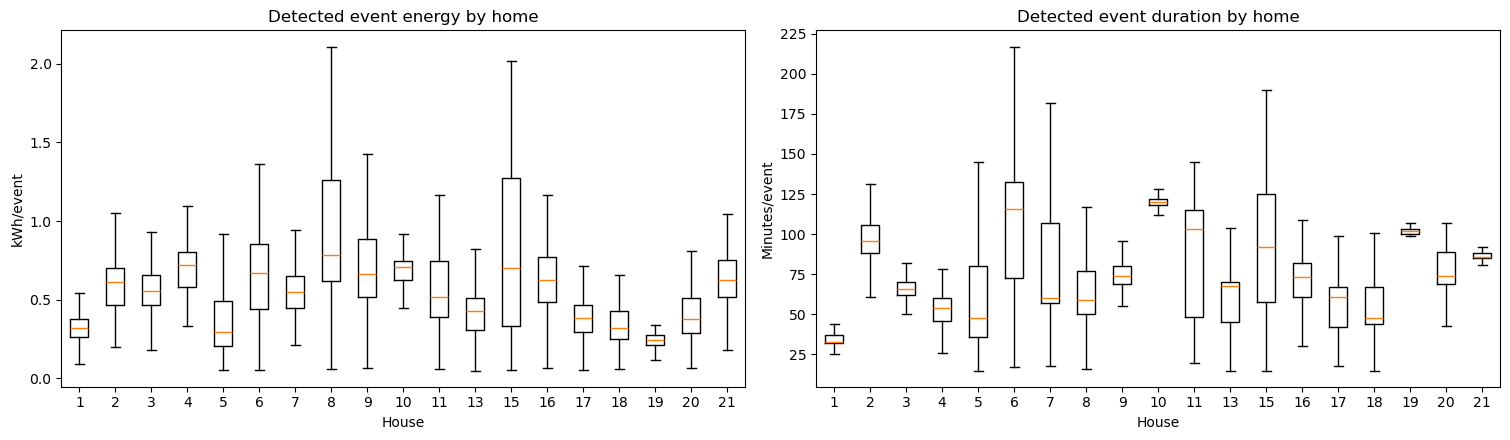

In [28]:
if len(cycles):
    selected=[h for h,n in cycles.groupby('house').size().items() if n>=3]
    if not selected: selected=sorted(cycles.house.unique().tolist())
    vals=[cycles.loc[cycles.house==h,'energy_kwh'].values for h in selected]
    dur=[cycles.loc[cycles.house==h,'duration_min'].values for h in selected]

    fig,axes=plt.subplots(1,2,figsize=(max(12,len(selected)*.8),4.5))
    axes[0].boxplot(vals,tick_labels=[str(h) for h in selected],showfliers=False)
    axes[1].boxplot(dur,tick_labels=[str(h) for h in selected],showfliers=False)
    axes[0].set(xlabel='House',ylabel='kWh/event',title='Detected event energy by home')
    axes[1].set(xlabel='House',ylabel='Minutes/event',title='Detected event duration by home')
    plt.tight_layout()
    fig.savefig(OUTPUT_DIR/'02_cross_house_cycles.png',dpi=160)
    plt.show()
else: 
    print('No events found under current threshold: report this and revisit coverage/thresholds.')